# Reproducing Figure 3 (panels F1, C1, C2) of Keskar et al., ICLR 2017
*On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima*

Written only from the paper's text. Protocol (Sec. 1.1 and 2.2): ADAM for both regimes, randomly sampled fixed-size
batches, SB = 256 points, LB = 10% of the training set, train until the training loss stops improving, then plot
f(α·x*_LB + (1−α)·x*_SB) and the accuracy for α ∈ [−1, 2] on the train and test sets.

**Run order:** Runtime → Change runtime type → GPU, then run cells 1 → 9.
**After a disconnect:** run cells 1–5 again, then continue. Cells 6 and 7 resume from the checkpoints and cached results in Drive.
Everything lives in `MyDrive/large_batch_repro/`.

## Cell 1 — Mount Drive, imports, configuration

In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT       = '/content/drive/MyDrive/large_batch_repro'
DATA_DIR   = os.path.join(ROOT, 'data')
CKPT_DIR   = os.path.join(ROOT, 'checkpoints')
RESULT_DIR = os.path.join(ROOT, 'results')
FIG_DIR    = os.path.join(ROOT, 'figures')
for _d in (DATA_DIR, CKPT_DIR, RESULT_DIR, FIG_DIR):
    os.makedirs(_d, exist_ok=True)

assert torch.cuda.is_available(), 'Enable a GPU: Runtime > Change runtime type'
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print('GPU:', torch.cuda.get_device_name(0))

CFG = {
    # ---- Protocol from Sec. 1.1 / 2.2 -------------------------------------
    'networks':    ['F1', 'C1', 'C2'],
    'sb_batch':    256,        # small batch: 256 data points
    'lb_fraction': 0.10,       # large batch: 10% of the training data
    'lr':          1e-3,       # ADAM in both regimes; step size not given in the paper -> ADAM default
    # "trained, without any budget or limits, until the loss function ceased to improve"
    # -> stop when the epoch training loss has not improved (relatively) for `patience` epochs,
    #    with a safety cap. LB makes only 10 steps per epoch, so it gets a larger cap.
    'max_epochs':  {'SB': 100, 'LB': 200},
    'patience':    10,
    'min_rel_improvement': 1e-3,
    'n_trials':    1,          # paper: 5 trials, one random SB/LB pair is plotted. 1 is enough for Fig. 3.
    # ---- Figure 3 -----------------------------------------------------------
    'alphas':      [round(float(a), 2) for a in np.linspace(-1.0, 2.0, 31)],
    # Batch-norm running statistics are not weights, so at each interpolated point they are
    # re-estimated on the training set ('recompute'). 'interpolate' mixes them like the weights.
    'bn_mode':     'recompute',
    'eval_batch':  2000,
    # ---- Engineering ----------------------------------------------------------
    'use_amp':     True,       # mixed precision for training only (bf16 on A100/L4, fp16 on T4); eval is fp32
    'lb_micro_batch': None,    # None = exact full-batch step. Set e.g. 1250 only if LB on C2 runs out of memory
                               # (gradients are then accumulated, but BN statistics come from the micro-batches).
    'ckpt_every':  1,          # epochs between checkpoints to Drive
}
with open(os.path.join(ROOT, 'config.json'), 'w') as f:
    json.dump(CFG, f, indent=2)
print('Working directory in Drive:', ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Working directory in Drive: /content/drive/MyDrive/large_batch_repro


## Cell 2 — Download the datasets into Drive (once) and cache them as compact `.npz` files in Drive

In [7]:
import torchvision
import shutil
import tarfile

DATASET_OF = {'F1': 'MNIST', 'C1': 'CIFAR10', 'C2': 'CIFAR10'}

def prepare_dataset(name):
    cache = os.path.join(DATA_DIR, f'{name}.npz')
    if os.path.exists(cache):
        print(f'{name}: cached at {cache}')
        return
    raw = os.path.join(DATA_DIR, 'raw')            # raw downloads also live in Drive
    os.makedirs(raw, exist_ok=True)
    if name == 'MNIST':
        tr = torchvision.datasets.MNIST(raw, train=True, download=True)
        te = torchvision.datasets.MNIST(raw, train=False, download=True)
        x_train, y_train = tr.data.numpy(), tr.targets.numpy()          # (N,28,28) uint8
        x_test,  y_test  = te.data.numpy(), te.targets.numpy()
    elif name == 'CIFAR10':
        # Force use of pre-downloaded tarball
        src_tar = '/content/drive/MyDrive/cifar-10-python.tar.gz'
        dst_tar = os.path.join(raw, 'cifar-10-python.tar.gz')

        # If the extracted directory doesn't exist, extract it manually
        extracted_dir = os.path.join(raw, 'cifar-10-batches-py')
        if not os.path.exists(extracted_dir):
            if os.path.exists(src_tar):
                print(f'Extracting local tarball {src_tar} to {raw}...')
                with tarfile.open(src_tar, 'r:gz') as tar:
                    tar.extractall(path=raw)
            else:
                # Fallback to copy if extraction directly isn't preferred
                if not os.path.exists(dst_tar):
                    print(f'Copying pre-downloaded {src_tar} to {dst_tar}')
                    shutil.copy(src_tar, dst_tar)

        # Setting download=True won't trigger download if files are extracted
        tr = torchvision.datasets.CIFAR10(raw, train=True, download=True)
        te = torchvision.datasets.CIFAR10(raw, train=False, download=True)
        x_train, y_train = tr.data.transpose(0, 3, 1, 2), np.array(tr.targets)   # (N,3,32,32) uint8
        x_test,  y_test  = te.data.transpose(0, 3, 1, 2), np.array(te.targets)
    else:
        raise ValueError(name)
    tmp = cache[:-4] + '_tmp.npz'
    np.savez(tmp,
             x_train=np.ascontiguousarray(x_train, dtype=np.uint8), y_train=y_train.astype(np.int64),
             x_test=np.ascontiguousarray(x_test, dtype=np.uint8),   y_test=y_test.astype(np.int64))
    os.replace(tmp, cache)
    print(f'{name}: train {x_train.shape}, test {x_test.shape} -> {cache}')

for ds in sorted({DATASET_OF[n] for n in CFG['networks']}):
    prepare_dataset(ds)

CIFAR10: cached at /content/drive/MyDrive/large_batch_repro/data/CIFAR10.npz
MNIST: cached at /content/drive/MyDrive/large_batch_repro/data/MNIST.npz


## Cell 3 — Load the cached data from Drive straight onto the GPU
The data sets are small, so they are kept on the GPU as `uint8` and random batches are taken by indexing,
which is far faster than a DataLoader for the 256-sample regime. Inputs are only scaled to [0, 1]
(the paper says the image sets are used without pre-processing).

In [8]:
_GPU_DATA = {}

def get_data(ds_name):
    if ds_name not in _GPU_DATA:
        z = np.load(os.path.join(DATA_DIR, f'{ds_name}.npz'))
        _GPU_DATA[ds_name] = {k: torch.from_numpy(z[k]).to(DEVICE) for k in z.files}
    return _GPU_DATA[ds_name]

def to_input(x_u8, ds_name):
    x = x_u8.float().div_(255.0)
    return x.flatten(1) if ds_name == 'MNIST' else x    # MNIST -> 784-dim vectors for the MLP

for ds in sorted({DATASET_OF[n] for n in CFG['networks']}):
    d = get_data(ds)
    print(ds, {k: tuple(v.shape) for k, v in d.items()})

CIFAR10 {'x_train': (50000, 3, 32, 32), 'y_train': (50000,), 'x_test': (10000, 3, 32, 32), 'y_test': (10000,)}
MNIST {'x_train': (60000, 28, 28), 'y_train': (60000,), 'x_test': (10000, 28, 28), 'y_test': (10000,)}


## Cell 4 — Networks (Appendix B)
* **F1** (B.1): 784 → 5 × [Linear 512, BN, ReLU] → 10.
* **C1** (B.3): 2 × [Conv 64 filters 5×5 stride 2, BN, ReLU, MaxPool(3)] → Dense 384 → Dense 192 → 10, BN everywhere,
  dropout with retention 0.5 on the two dense layers. "MaxPool(3)" is read as a 3×3 window with stride 2 (overlapping pooling).
* **C2** (B.4): VGG stacks 2×64, 2×128, 3×256, 3×512, 3×512 (3×3, stride 1), MaxPool(2) after each stack → Dense 512 → 10,
  same BN/ReLU/dropout as C1.

BN is placed between the affine map and the ReLU and is not applied to the output layer (softmax is inside the cross-entropy).
Default PyTorch initialisation is uniform, matching "uniformly distributed random starting points".

In [9]:
def fc_bn_relu(i, o):
    return [nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU(inplace=True)]

def conv_bn_relu(cin, cout, k, stride):
    return [nn.Conv2d(cin, cout, k, stride=stride, padding=k // 2), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

def build_F1(num_classes=10):
    layers, d = [], 784
    for _ in range(5):
        layers += fc_bn_relu(d, 512)
        d = 512
    layers.append(nn.Linear(d, num_classes))
    return nn.Sequential(*layers)

def build_C1(num_classes=10):
    layers, c = [], 3
    for _ in range(2):
        layers += conv_bn_relu(c, 64, 5, 2)
        layers.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
        c = 64
    # spatial size 32 -> 16 -> 8 -> 4 -> 2, so 64*2*2 = 256 features
    layers += [nn.Flatten(),
               *fc_bn_relu(64 * 2 * 2, 384), nn.Dropout(0.5),
               *fc_bn_relu(384, 192),        nn.Dropout(0.5),
               nn.Linear(192, num_classes)]
    return nn.Sequential(*layers)

def build_C2(num_classes=10):
    layers, c = [], 3
    for n, width in [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)]:
        for _ in range(n):
            layers += conv_bn_relu(c, width, 3, 1)
            c = width
        layers.append(nn.MaxPool2d(2))
    # spatial size 32 -> 1 after five poolings, so 512 features
    layers += [nn.Flatten(), *fc_bn_relu(512, 512), nn.Dropout(0.5), nn.Linear(512, num_classes)]
    return nn.Sequential(*layers)

def build_model(net):
    return {'F1': build_F1, 'C1': build_C1, 'C2': build_C2}[net]()

for net in CFG['networks']:
    m = build_model(net).to(DEVICE).eval()
    x = torch.zeros(4, 784) if net == 'F1' else torch.zeros(4, 3, 32, 32)
    with torch.no_grad():
        out = m(x.to(DEVICE))
    print(f'{net}: {sum(p.numel() for p in m.parameters()):,} parameters, output {tuple(out.shape)}')
del m

F1: 1,462,794 parameters, output (4, 10)
C1: 283,274 parameters, output (4, 10)
C2: 14,991,946 parameters, output (4, 10)


## Cell 5 — Training with checkpoint/resume in Drive
* SB and LB runs of the same trial start from the **same** initial point x0 (the paper compares ‖x*−x0‖ for both),
  but use different batch orders.
* Each epoch is a random permutation cut into fixed-size batches (|B_k| constant), leftovers are dropped.
* A checkpoint (`last.pt`: weights, ADAM state, scaler, RNG state, history) is written to Drive every epoch,
  and `final.pt` when the run ends. A finished run is never retrained.

In [10]:
NET_ID = {'F1': 1, 'C1': 2, 'C2': 3}

def init_seed(net, trial):            # shared by SB and LB of a trial -> same x0
    return 1000 * NET_ID[net] + trial

def data_seed(net, trial, regime):
    return 10 * init_seed(net, trial) + (1 if regime == 'LB' else 2)

def run_dir(net, regime, trial):
    d = os.path.join(CKPT_DIR, f'{net}_{regime}_trial{trial}')
    os.makedirs(d, exist_ok=True)
    return d

def atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

def atomic_json_save(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'w') as f:
        json.dump(obj, f, indent=1)
    os.replace(tmp, path)

def amp_dtype():
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

@torch.no_grad()
def evaluate(model, x_all, y_all, ds_name, bs=None):
    """Mean cross-entropy f(x) and accuracy (%) over a whole data set; eval mode, fp32."""
    bs = bs or CFG['eval_batch']
    model.eval()
    loss_sum = torch.zeros((), device=DEVICE, dtype=torch.float64)
    correct = torch.zeros((), device=DEVICE, dtype=torch.long)
    for i in range(0, len(y_all), bs):
        xb, yb = to_input(x_all[i:i + bs], ds_name), y_all[i:i + bs]
        out = model(xb).float()
        loss_sum += F.cross_entropy(out, yb, reduction='sum').double()
        correct += (out.argmax(1) == yb).sum()
    n = len(y_all)
    return loss_sum.item() / n, 100.0 * correct.item() / n

def train_run(net, regime, trial):
    d = run_dir(net, regime, trial)
    final_path, last_path = os.path.join(d, 'final.pt'), os.path.join(d, 'last.pt')
    if os.path.exists(final_path):
        ck = torch.load(final_path, map_location='cpu', weights_only=False)
        m = ck['metrics']
        print(f'[{net} {regime} t{trial}] cached: train acc {m["train_acc"]:.2f}%, test acc {m["test_acc"]:.2f}% '
              f'({ck["epochs"]} epochs, batch {ck["batch_size"]})')
        return ck

    ds = DATASET_OF[net]
    data = get_data(ds)
    xtr, ytr, xte, yte = data['x_train'], data['y_train'], data['x_test'], data['y_test']
    N = len(ytr)
    B = CFG['sb_batch'] if regime == 'SB' else int(round(CFG['lb_fraction'] * N))
    steps = N // B
    micro = CFG['lb_micro_batch'] if regime == 'LB' else None

    torch.manual_seed(init_seed(net, trial))
    model = build_model(net).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'])
    dt, use_amp = amp_dtype(), CFG['use_amp']
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp and dt == torch.float16)
    gen = torch.Generator(device=DEVICE)
    gen.manual_seed(data_seed(net, trial, regime))
    st = {'epoch': 0, 'best': float('inf'), 'bad': 0, 'history': []}

    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        scaler.load_state_dict(ck['scaler'])
        gen.set_state(ck['gen'])
        st = ck['st']
        print(f'[{net} {regime} t{trial}] resuming after epoch {st["epoch"]}')
    else:
        print(f'[{net} {regime} t{trial}] new run: batch {B}, {steps} steps/epoch')

    max_ep = CFG['max_epochs'][regime]
    stopped = st['bad'] >= CFG['patience']
    while st['epoch'] < max_ep and not stopped:
        model.train()
        t0 = time.time()
        perm = torch.randperm(N, device=DEVICE, generator=gen)
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE, dtype=torch.long)
        for s in range(steps):
            idx = perm[s * B:(s + 1) * B]
            opt.zero_grad(set_to_none=True)
            for ch in (idx.split(micro) if micro else (idx,)):
                xb, yb = to_input(xtr[ch], ds), ytr[ch]
                with torch.autocast('cuda', dtype=dt, enabled=use_amp):
                    out = model(xb)
                loss = F.cross_entropy(out.float(), yb)
                scaler.scale(loss * (len(ch) / B)).backward()
                loss_sum += loss.detach() * len(ch)
                correct += (out.argmax(1) == yb).sum()
            scaler.step(opt)
            scaler.update()

        tr_loss = loss_sum.item() / (steps * B)
        tr_acc = 100.0 * correct.item() / (steps * B)
        if not np.isfinite(tr_loss):
            raise RuntimeError('Training loss is not finite')
        te_loss, te_acc = evaluate(model, xte, yte, ds)
        st['epoch'] += 1
        if tr_loss < st['best'] * (1.0 - CFG['min_rel_improvement']):
            st['best'], st['bad'] = tr_loss, 0
        else:
            st['bad'] += 1
        stopped = st['bad'] >= CFG['patience']
        st['history'].append({'epoch': st['epoch'], 'train_loss_running': tr_loss, 'train_acc_running': tr_acc,
                              'test_loss': te_loss, 'test_acc': te_acc, 'seconds': time.time() - t0})
        print(f'  ep {st["epoch"]:3d} | train loss {tr_loss:.4f} acc {tr_acc:6.2f}% | '
              f'test acc {te_acc:6.2f}% | no-improve {st["bad"]:2d} | {time.time() - t0:5.1f}s')
        if st['epoch'] % CFG['ckpt_every'] == 0 or stopped or st['epoch'] == max_ep:
            atomic_torch_save({'model': model.state_dict(), 'opt': opt.state_dict(),
                               'scaler': scaler.state_dict(), 'gen': gen.get_state(), 'st': st}, last_path)

    tr_loss, tr_acc = evaluate(model, xtr, ytr, ds)
    te_loss, te_acc = evaluate(model, xte, yte, ds)
    ck = {'state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
          'metrics': {'train_loss': tr_loss, 'train_acc': tr_acc, 'test_loss': te_loss, 'test_acc': te_acc},
          'batch_size': B, 'epochs': st['epoch'], 'history': st['history'],
          'stopped_by': 'plateau' if stopped else 'max_epochs'}
    atomic_torch_save(ck, final_path)
    atomic_json_save({k: ck[k] for k in ('metrics', 'batch_size', 'epochs', 'stopped_by', 'history')},
                     os.path.join(d, 'summary.json'))
    if os.path.exists(last_path):
        os.remove(last_path)
    print(f'[{net} {regime} t{trial}] done ({ck["stopped_by"]}): train acc {tr_acc:.2f}%, test acc {te_acc:.2f}%')
    return ck

## Cell 6 — Train the SB and LB models
Re-running this cell after a disconnect resumes unfinished runs and simply loads finished ones.
To spread the work over sessions, set `CFG['networks']` to one network at a time.

In [11]:
TRAINED = {}
for net in CFG['networks']:
    for trial in range(CFG['n_trials']):
        for regime in ('SB', 'LB'):
            TRAINED[(net, regime, trial)] = train_run(net, regime, trial)
            torch.cuda.empty_cache()

[F1 SB t0] new run: batch 256, 234 steps/epoch
  ep   1 | train loss 0.1825 acc  94.50% | test acc  96.84% | no-improve  0 |   1.7s
  ep   2 | train loss 0.0804 acc  97.46% | test acc  97.39% | no-improve  0 |   1.1s
  ep   3 | train loss 0.0554 acc  98.25% | test acc  97.74% | no-improve  0 |   1.1s
  ep   4 | train loss 0.0442 acc  98.59% | test acc  97.77% | no-improve  0 |   1.0s
  ep   5 | train loss 0.0361 acc  98.84% | test acc  97.72% | no-improve  0 |   1.1s
  ep   6 | train loss 0.0274 acc  99.16% | test acc  97.83% | no-improve  0 |   1.2s
  ep   7 | train loss 0.0247 acc  99.21% | test acc  97.82% | no-improve  0 |   1.2s
  ep   8 | train loss 0.0233 acc  99.25% | test acc  97.74% | no-improve  0 |   1.1s
  ep   9 | train loss 0.0201 acc  99.32% | test acc  98.19% | no-improve  0 |   1.1s
  ep  10 | train loss 0.0164 acc  99.47% | test acc  98.13% | no-improve  0 |   1.2s
  ep  11 | train loss 0.0161 acc  99.50% | test acc  98.28% | no-improve  0 |   1.2s
  ep  12 | train l

## Cell 7 — Parametric 1-D plots: f(α·x*_LB + (1−α)·x*_SB), α ∈ [−1, 2]
For every α the loss and accuracy are measured on the full training and test sets. Each α is saved to a JSON file in
Drive as soon as it is computed, so an interrupted sweep continues where it stopped.

In [12]:
BN_TYPES = (nn.BatchNorm1d, nn.BatchNorm2d)

@torch.no_grad()
def recompute_bn_stats(model, x_all, ds_name, bs=None):
    """Re-estimate BN running mean/var for the current weights on the training set (dropout stays off)."""
    bs = bs or CFG['eval_batch']
    bns = [m for m in model.modules() if isinstance(m, BN_TYPES)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None                     # cumulative average over all batches
    model.eval()
    for m in bns:
        m.train()
    for i in range(0, len(x_all), bs):
        model(to_input(x_all[i:i + bs], ds_name))
    for m in bns:
        m.momentum = 0.1
    model.eval()

def interpolate(sd_s, sd_l, alpha):
    out = {}
    for k, vs in sd_s.items():
        if not torch.is_floating_point(vs):   # num_batches_tracked
            out[k] = vs.clone()
            continue
        v = alpha * sd_l[k] + (1.0 - alpha) * vs
        if k.endswith('running_var'):         # extrapolation could make a variance negative
            v = v.clamp_min(1e-5)
        out[k] = v
    return out

def pick_pair(net):
    """'we randomly chose a pair of SB and LB minimizers from the 5 trials'"""
    rng = random.Random(NET_ID[net])
    return rng.randrange(CFG['n_trials']), rng.randrange(CFG['n_trials'])

def parametric_sweep(net):
    ts, tl = pick_pair(net)
    mode = CFG['bn_mode']
    path = os.path.join(RESULT_DIR, f'fig3_{net}_SBt{ts}_LBt{tl}_{mode}.json')
    res = {}
    if os.path.exists(path):
        with open(path) as f:
            res = json.load(f)
    todo = [a for a in CFG['alphas'] if f'{a:.2f}' not in res]
    print(f'{net}: SB trial {ts}, LB trial {tl}, {len(res)} cached / {len(todo)} to compute')
    if not todo:
        return res

    ds = DATASET_OF[net]
    data = get_data(ds)
    load = lambda r, t: {k: v.to(DEVICE) for k, v in torch.load(
        os.path.join(run_dir(net, r, t), 'final.pt'), map_location='cpu', weights_only=False)['state_dict'].items()}
    sd_s, sd_l = load('SB', ts), load('LB', tl)
    model = build_model(net).to(DEVICE)

    for a in todo:
        t0 = time.time()
        model.load_state_dict(interpolate(sd_s, sd_l, a))
        if mode == 'recompute':
            recompute_bn_stats(model, data['x_train'], ds)
        tr_loss, tr_acc = evaluate(model, data['x_train'], data['y_train'], ds)
        te_loss, te_acc = evaluate(model, data['x_test'], data['y_test'], ds)
        res[f'{a:.2f}'] = {'alpha': a, 'train_loss': tr_loss, 'train_acc': tr_acc,
                           'test_loss': te_loss, 'test_acc': te_acc}
        atomic_json_save(res, path)
        print(f'  alpha {a:+.2f} | train {tr_loss:8.4f} / {tr_acc:6.2f}% | '
              f'test {te_loss:8.4f} / {te_acc:6.2f}% | {time.time() - t0:4.1f}s')
    return res

FIG3 = {net: parametric_sweep(net) for net in CFG['networks']}

F1: SB trial 0, LB trial 0, 0 cached / 31 to compute
  alpha -1.00 | train   0.0039 /  99.87% | test   0.0904 /  98.35% |  0.2s
  alpha -0.90 | train   0.0027 /  99.91% | test   0.0861 /  98.43% |  0.2s
  alpha -0.80 | train   0.0019 /  99.94% | test   0.0822 /  98.51% |  0.2s
  alpha -0.70 | train   0.0015 /  99.97% | test   0.0788 /  98.61% |  0.2s
  alpha -0.60 | train   0.0012 /  99.97% | test   0.0759 /  98.62% |  0.2s
  alpha -0.50 | train   0.0010 /  99.97% | test   0.0732 /  98.67% |  0.2s
  alpha -0.40 | train   0.0009 /  99.98% | test   0.0708 /  98.70% |  0.2s
  alpha -0.30 | train   0.0008 /  99.98% | test   0.0686 /  98.74% |  0.2s
  alpha -0.20 | train   0.0007 /  99.98% | test   0.0667 /  98.76% |  0.2s
  alpha -0.10 | train   0.0007 /  99.98% | test   0.0650 /  98.73% |  0.2s
  alpha +0.00 | train   0.0007 /  99.98% | test   0.0635 /  98.76% |  0.2s
  alpha +0.10 | train   0.0007 /  99.98% | test   0.0623 /  98.73% |  0.2s
  alpha +0.20 | train   0.0007 /  99.98% | test

## Cell 8 — Plot the panels in the style of Figure 3
Left axis (blue): cross-entropy. Right axis (red): accuracy. Solid = training set, dashed = test set.
α = 0 is the SB minimizer, α = 1 the LB minimizer. Figures are saved to Drive.

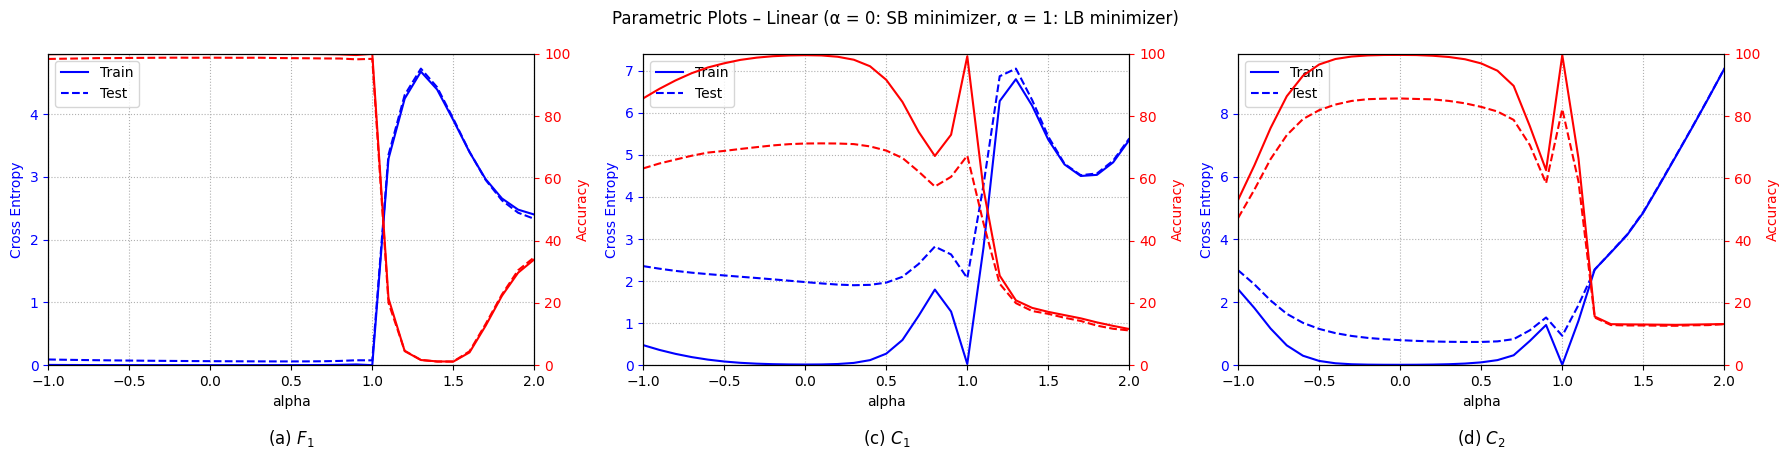

In [13]:
import matplotlib.pyplot as plt

PANEL = {'F1': '(a) $F_1$', 'C1': '(c) $C_1$', 'C2': '(d) $C_2$'}

def plot_panel(ax, res, title):
    keys = sorted(res, key=float)
    a = [float(k) for k in keys]
    get = lambda field: [res[k][field] for k in keys]
    l1, = ax.plot(a, get('train_loss'), 'b-', label='Train')
    l2, = ax.plot(a, get('test_loss'), 'b--', label='Test')
    ax.set_xlim(-1, 2)
    ax.set_ylim(bottom=0)
    ax.set_xlabel('alpha')
    ax.set_ylabel('Cross Entropy', color='b')
    ax.tick_params(axis='y', colors='b')
    ax.grid(True, linestyle=':')
    ax2 = ax.twinx()
    ax2.plot(a, get('train_acc'), 'r-')
    ax2.plot(a, get('test_acc'), 'r--')
    ax2.set_ylim(0, 100)
    ax2.set_ylabel('Accuracy', color='r')
    ax2.tick_params(axis='y', colors='r')
    ax.legend(handles=[l1, l2], loc='upper left')
    ax.set_title(title, y=-0.28)

nets = [n for n in CFG['networks'] if n in FIG3]
fig, axes = plt.subplots(1, len(nets), figsize=(6 * len(nets), 4.8), squeeze=False)
for ax, net in zip(axes[0], nets):
    plot_panel(ax, FIG3[net], PANEL.get(net, net))
fig.suptitle('Parametric Plots – Linear (α = 0: SB minimizer, α = 1: LB minimizer)')
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'figure3_{"_".join(nets)}_{CFG["bn_mode"]}.{ext}'),
                dpi=200, bbox_inches='tight')
plt.show()

## Cell 9 — Sanity check against Table 2 and the ‖x* − x0‖ ratio from Section 3

In [14]:
PAPER_T2 = {  # SB train, LB train, SB test, LB test (Table 2)
    'F1': (99.66, 99.92, 98.03, 97.81),
    'C1': (99.89, 99.66, 80.04, 77.26),
    'C2': (99.99, 99.99, 89.24, 87.26),
}

def param_vector(state_dict, names):
    return torch.cat([state_dict[k].float().flatten().cpu() for k in names])

print(f'{"net":4} {"trial":5} | {"train SB":>9} {"train LB":>9} | {"test SB":>8} {"test LB":>8} | '
      f'{"paper test SB/LB":>17} | {"||xs-x0||/||xl-x0||":>20}')
for net in CFG['networks']:
    for trial in range(CFG['n_trials']):
        sb = train_run(net, 'SB', trial) if (net, 'SB', trial) not in TRAINED else TRAINED[(net, 'SB', trial)]
        lb = train_run(net, 'LB', trial) if (net, 'LB', trial) not in TRAINED else TRAINED[(net, 'LB', trial)]
        torch.manual_seed(init_seed(net, trial))
        m0 = build_model(net)
        names = [k for k, _ in m0.named_parameters()]
        x0 = param_vector(m0.state_dict(), names)
        xs = param_vector(sb['state_dict'], names)
        xl = param_vector(lb['state_dict'], names)
        ratio = (xs - x0).norm() / (xl - x0).norm()
        s, l = sb['metrics'], lb['metrics']
        p = PAPER_T2[net]
        print(f'{net:4} {trial:5} | {s["train_acc"]:8.2f}% {l["train_acc"]:8.2f}% | '
              f'{s["test_acc"]:7.2f}% {l["test_acc"]:7.2f}% | {p[2]:7.2f}% / {p[3]:6.2f}% | {ratio.item():20.2f}')

net  trial |  train SB  train LB |  test SB  test LB |  paper test SB/LB |  ||xs-x0||/||xl-x0||
F1       0 |    99.98%   100.00% |   98.72%   98.38% |   98.03% /  97.81% |                 9.22
C1       0 |    96.63%    93.95% |   68.98%   64.50% |   80.04% /  77.26% |                 3.48
C2       0 |    99.08%    98.65% |   84.84%   81.26% |   89.24% /  87.26% |                 7.43
